# Chess judge accuracy by proposer/judge pairing

Set `EXP_DIR` below and run all cells. This notebook shows overall judge correctness, stacked decision rates by pairing, and accuracy by puzzle difficulty bucket.

A **positive** judgement is `Yes` (accept the proposed solution); the ground truth is the saved `proposer_correct` label.

| Outcome | Meaning | Rate denominator |
|---|---|---|
| False positive (FP) | Accept an incorrect proposal | All incorrect proposals with valid decisions: FP + TN |
| False negative (FN) | Reject a correct proposal | All correct proposals with valid decisions: FN + TP |
| True positive (TP) | Accept a correct proposal | All correct proposals with valid decisions: TP + FN |
| True negative (TN) | Reject an incorrect proposal | All incorrect proposals with valid decisions: TN + FP |

These are **conditional rates**: FP + TN = 100% and FN + TP = 100%. Each full bar has length equal to its ground-truth class count, so differently sized classes remain visible. Segment labels show the conditional percentages. A missing ground-truth class is shown as `N/A (n=0)`, never a 0% rate.

Only completed judgements ending in `Yes` or `No` (allowing surrounding punctuation and Markdown such as `No.`, `**Yes**`, or `No**`) with a normal final stop are included in the confusion-matrix rates. Incomplete, malformed, truncated, refused, and unverifiable decisions are counted separately in the table. Consequently, these rates describe valid binary decisions and can differ from the runner's overall accuracy, which counts malformed/truncated/refused completed judgements as incorrect. Partial runs can have unrepresentative class counts.

**Overall accuracy** is `(TP + TN) / puzzles seen`. A puzzle is seen if it is complete or has a saved response, trace, error, API call, or token usage. Invalid, truncated, refused, and failed attempts count as incorrect. Untouched checkpoint rows are excluded. Overall accuracy appears in the initial table and beside each pairing in the stacked chart. Difficulty-bucket accuracy uses the same rule.

The tool-use table reports total validator calls, calls that returned an illegal move, and how many puzzle attempts used the validator, by proposer and judge.


In [ ]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

repo_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "core").is_dir())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
from core.chess.protocols.judge import normalize_judgement, score_judgement
EXP_DIR = repo_root / "exp" / "chess_six_judged_luna"
# Also accepts an end-to-end experiment root, its judgements/ directory,
# a judge/ directory, or a single judge/source directory containing puzzles.csv.
FIGURE_DIR = EXP_DIR / "figures"


In [12]:
def find_judge_files(directory):
    directory = Path(directory)
    if (directory / "judgements" / "judge").is_dir():
        root = directory / "judgements" / "judge"
    elif (directory / "judge").is_dir():
        root = directory / "judge"
    else:
        root = directory
    paths = [root / "puzzles.csv"] if (root / "puzzles.csv").is_file() else sorted(root.glob("*/puzzles.csv"))
    if not paths:
        raise FileNotFoundError(f"No judge puzzles.csv files found in {directory}")
    return paths


def has_normal_final_stop(value):
    try:
        trace = json.loads(value)
        responses = [entry for entry in trace if isinstance(entry, dict) and "completion" in entry]
        final = responses[-1]
        return not final.get("tool_calls") and final.get("stop_reason") in (
            "STOP_SEQUENCE", "stop", "end_turn", "completed",
        )
    except (ValueError, TypeError, IndexError):
        return False


def saved_judgement(row):
    try:
        trace = json.loads(row.get("tool_trace", "[]"))
        final = [entry for entry in trace if isinstance(entry, dict) and "completion" in entry][-1]
        return normalize_judgement(final["completion"])
    except (ValueError, TypeError, KeyError, IndexError):
        return normalize_judgement(str(row["judgement"]))


def summarize_judgements(raw, by_bucket=False):
    required = {"model", "proposer", "complete", "proposer_correct", "judgement"}
    if by_bucket:
        required.add("rating_bucket")
    if not required.issubset(raw.columns):
        raise ValueError(f"Missing judge columns: {sorted(required - set(raw.columns))}")
    df = raw.copy()
    df["judgement"] = df.apply(saved_judgement, axis=1)
    if df[["model", "proposer"]].isna().any().any() or df[["model", "proposer"]].eq("").any().any():
        raise ValueError("Judge model and proposer must be present on every row")
    for column in ("complete", "proposer_correct"):
        values = df[column].astype(str).str.lower()
        if not values.isin(["true", "false"]).all():
            raise ValueError(f"{column} must contain only True/False")
        df[column] = values.eq("true")
    trace = df["tool_trace"] if "tool_trace" in df else pd.Series("", index=df.index)
    df["valid"] = (df["complete"] & df["judgement"].isin(["Yes", "No"])
                   & trace.map(has_normal_final_stop))
    df["seen"] = df["complete"] | ~trace.fillna("").astype(str).str.strip().isin(["", "[]", "null"])
    for column in ("model_response", "error"):
        if column in df:
            df["seen"] |= df[column].fillna("").astype(str).str.strip().ne("")
    for column in ("api_calls", "input_tokens", "output_tokens"):
        if column in df:
            df["seen"] |= pd.to_numeric(df[column], errors="coerce").fillna(0).gt(0)
    groups = ["proposer", "model"] + (["rating_bucket"] if by_bucket else [])
    records = []
    for keys, group in df.groupby(groups, sort=True):
        proposer, judge = keys[:2]
        valid = group[group["valid"]]
        actual = valid["proposer_correct"]
        accepted = valid["judgement"].eq("Yes")
        tp = int((actual & accepted).sum())
        fn = int((actual & ~accepted).sum())
        fp = int((~actual & accepted).sum())
        tn = int((~actual & ~accepted).sum())
        positive, negative = tp + fn, fp + tn
        seen = int(group["seen"].sum())
        records.append(dict(
            proposer=proposer, judge=judge,
            **({"rating_bucket": keys[2]} if by_bucket else {}),
            planned=len(group), seen=seen, correct_judgements=tp + tn,
            accuracy=(tp + tn) / seen if seen else np.nan,
            incomplete=int((~group["complete"]).sum()),
            invalid_completed=int((group["complete"] & ~group["valid"]).sum()),
            valid=len(valid), correct_proposals=positive, incorrect_proposals=negative,
            FP=fp, FN=fn, TP=tp, TN=tn,
            FPR=fp / negative if negative else np.nan,
            FNR=fn / positive if positive else np.nan,
            TPR=tp / positive if positive else np.nan,
            TNR=tn / negative if negative else np.nan,
        ))
    return pd.DataFrame(records)


In [13]:
paths = find_judge_files(EXP_DIR)
raw = pd.concat([
    pd.read_csv(path, keep_default_na=False, dtype={"puzzleId": str, "model": str, "proposer": str}).assign(_result_file=str(path.resolve()))
    for path in paths
], ignore_index=True)
summary = summarize_judgements(raw)
if summary.empty:
    raise ValueError("The judge result files contain no puzzle rows yet.")
print(f"Loaded {len(raw):,} rows from {len(paths)} files: {EXP_DIR}")
print("Overall accuracy = correct judgements / puzzles seen; invalid and failed attempts count as incorrect.")
print("Confusion-matrix class counts and conditional rates use valid decisions only.")
display(summary.style.format({key: "{:.1%}" for key in ["accuracy", "FPR", "FNR", "TPR", "TNR"]}, na_rep="N/A"))


tool_fields = ["validate_move_sequence_calls", "validate_move_sequence_illegal_calls"]
tool_usage = raw.reindex(columns=tool_fields).apply(pd.to_numeric, errors="coerce")
tool_usage["puzzles_using_validator"] = tool_usage[tool_fields[0]].gt(0).where(
    tool_usage[tool_fields[0]].notna()
)
display(tool_usage.groupby([raw["proposer"], raw["model"].rename("judge")]).sum(min_count=1))


Loaded 900 rows from 6 files: /Users/jacksonsubcleff/llm_debate/exp/chess_six_judged
Overall accuracy = correct judgements / puzzles seen; invalid and failed attempts count as incorrect.
Confusion-matrix class counts and conditional rates use valid decisions only.


,proposer,judge,planned,seen,correct_judgements,accuracy,incomplete,invalid_completed,valid,correct_proposals,incorrect_proposals,FP,FN,TP,TN,FPR,FNR,TPR,TNR
0,openai/gpt-oss-120b,claude-haiku-5-5,150,150,115,76.7%,0,0,150,49,101,18,17,32,83,17.8%,34.7%,65.3%,82.2%
1,openai/gpt-oss-120b,claude-sonnet-5-5,150,150,118,78.7%,0,2,148,49,99,20,10,39,79,20.2%,20.4%,79.6%,79.8%
2,openai/gpt-oss-120b,gpt-6-luna,150,150,85,56.7%,0,27,123,46,77,32,6,40,45,41.6%,13.0%,87.0%,58.4%
3,openai/gpt-oss-120b,gpt-6.1-sol,150,150,121,80.7%,0,1,149,49,100,25,3,46,75,25.0%,6.1%,93.9%,75.0%
4,openai/gpt-oss-120b,openai/gpt-oss-120b,150,150,107,71.3%,0,0,150,49,101,24,19,30,77,23.8%,38.8%,61.2%,76.2%
5,openai/gpt-oss-120b,openai/gpt-oss-20b,150,150,49,32.7%,0,80,70,29,41,6,15,14,35,14.6%,51.7%,48.3%,85.4%


validate_move_sequence_calls  \
proposer            judge                                               
openai/gpt-oss-120b claude-haiku-5-5                               17   
                    claude-sonnet-5-5                               1   
                    gpt-6-luna                                     73   
                    gpt-6.1-sol                                   211   
                    openai/gpt-oss-120b                            12   
                    openai/gpt-oss-20b                              4   

                                         validate_move_sequence_illegal_calls  \
proposer            judge                                                       
openai/gpt-oss-120b claude-haiku-5-5                                        6   
                    claude-sonnet-5-5                                       1   
                    gpt-6-luna                                             13   
                    gpt-6.1-sol                                            20   
                    openai/gpt-oss-120b                                     0   
                    openai/gpt-oss-20b                                      0   

                                         puzzles_using_validator  
proposer            judge                                         
openai/gpt-oss-120b claude-haiku-5-5                          13  
                    claude-sonnet-5-5                          1  
                    gpt-6-luna                                52  
                    gpt-6.1-sol                              135  
                    openai/gpt-oss-120b                       12  
                    openai/gpt-oss-20b                         4

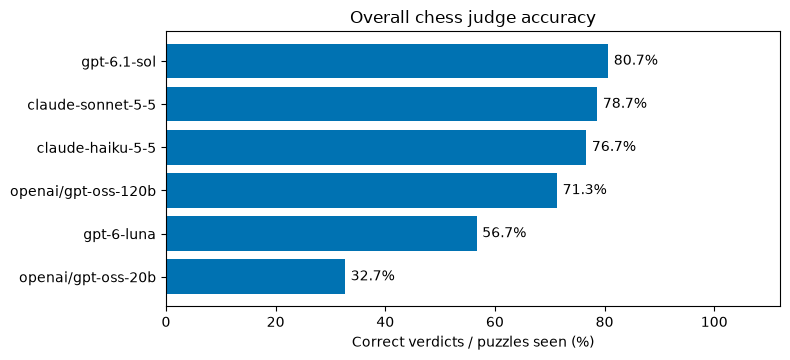

In [14]:
overall = summary.groupby("judge")[["correct_judgements", "seen"]].sum()
overall = overall.loc[overall["seen"] > 0].copy()
if overall.empty:
    print("No judges have seen any puzzles yet.")
else:
    overall["accuracy_pct"] = 100 * overall["correct_judgements"] / overall["seen"]
    overall = overall.sort_values("accuracy_pct", ascending=False)
    fig, ax = plt.subplots(figsize=(8, max(3, len(overall) * 0.45 + 1)))
    bars = ax.barh(overall.index, overall["accuracy_pct"], color="#0072B2")
    ax.bar_label(bars, fmt="%.1f%%", padding=4)
    ax.invert_yaxis()
    ax.set(xlim=(0, 112), xticks=np.arange(0, 101, 20),
           xlabel="Correct verdicts / puzzles seen (%)", title="Overall chess judge accuracy")
    fig.tight_layout()
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / "judge_overall_accuracy.png", dpi=200, bbox_inches="tight")
    plt.show()


## Decision rates and ground-truth class sizes

Each pairing has two adjacent horizontal stacked bars: **TN + FP** for incorrect proposals and **TP + FN** for correct proposals. Bar lengths and segment widths are puzzle counts on a shared axis; the percentages inside segments use the corresponding class total. End labels show each class and its count. Small segments may omit their interior percentage to keep labels readable; exact rates remain in the table above. Zero-size classes show `N/A (n=0)`. Re-run the loading and plotting cells to refresh an experiment still in progress.

Each pairing label also gives **overall accuracy (correct / seen)**, which includes invalid and failed responses in its denominator. The stacked bars continue to show valid binary decisions only.


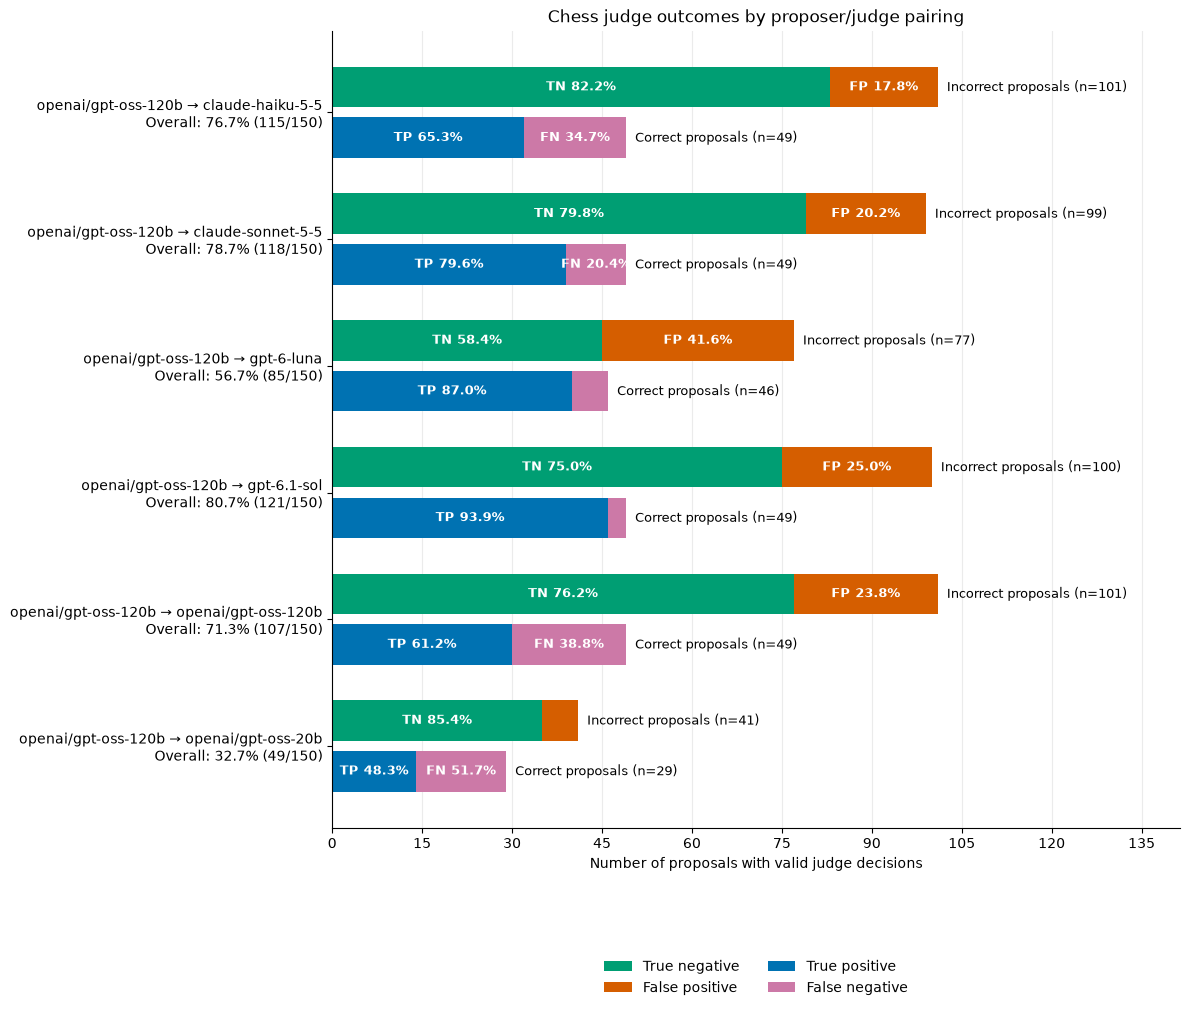

Saved chart: /Users/jacksonsubcleff/llm_debate/exp/chess_six_judged/figures/judge_decision_rates.png


In [15]:
colors = {"TN": "#009E73", "FP": "#D55E00", "TP": "#0072B2", "FN": "#CC79A7"}
classes = [
    ("Incorrect proposals", "incorrect_proposals", "TN", "FP", -0.2),
    ("Correct proposals", "correct_proposals", "TP", "FN", 0.2),
]
y = np.arange(len(summary))
height = 0.32
max_class = max(1, int(summary[["correct_proposals", "incorrect_proposals"]].to_numpy().max()))
fig, ax = plt.subplots(figsize=(12, max(4.5, len(summary) * 1.45 + 1.5)))
for class_label, total_column, first, second, offset in classes:
    positions = y + offset
    totals = summary[total_column].to_numpy(dtype=int)
    first_counts = summary[first].to_numpy(dtype=int)
    second_counts = summary[second].to_numpy(dtype=int)
    ax.barh(positions, first_counts, height=height, color=colors[first], label=first)
    ax.barh(positions, second_counts, left=first_counts, height=height, color=colors[second], label=second)
    for position, total, left_count, right_count in zip(positions, totals, first_counts, second_counts):
        if total == 0:
            ax.text(max_class * 0.015, position, f"{class_label}: N/A (n=0)",
                    va="center", fontsize=9, color="#666666")
            continue
        for outcome, left, count in [(first, 0, left_count), (second, left_count, right_count)]:
            # Tiny segments retain their count width; their exact rates are in the table.
            if count >= max_class * 0.08:
                ax.text(left + count / 2, position, f"{outcome} {count / total:.1%}",
                        ha="center", va="center", fontsize=9, color="white", fontweight="bold")
        ax.text(total + max_class * 0.015, position, f"{class_label} (n={total})",
                va="center", fontsize=9)
labels = [
    f"{row.proposer} → {row.judge}\n"
    + (f"Overall: {row.accuracy:.1%} ({row.correct_judgements}/{row.seen})"
       if row.seen else "Overall: N/A (0 seen)")
    for row in summary.itertuples()
]
ax.set(yticks=y, yticklabels=labels, xlim=(0, max_class * 1.4),
       xlabel="Number of proposals with valid judge decisions",
       title="Chess judge outcomes by proposer/judge pairing")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.invert_yaxis()
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["True negative", "False positive", "True positive", "False negative"],
          loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
output_path = FIGURE_DIR / "judge_decision_rates.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved chart: {output_path}")


## Judge accuracy overall and by puzzle difficulty

Low: rating < 1300; Medium: 1300–2300 inclusive; High: > 2300. Each bar is correct judgements divided by puzzles seen in that bucket, **including invalid and failed attempts as incorrect**. Bar labels show the percentage and correct/seen counts. Missing or unattempted buckets are `N/A`. Partial runs may have different bucket sample sizes.


,proposer,judge,rating_bucket,planned,seen,correct_judgements,accuracy,incomplete,invalid_completed,valid,correct_proposals,incorrect_proposals,FP,FN,TP,TN,FPR,FNR,TPR,TNR
0,openai/gpt-oss-120b,claude-haiku-5-5,High,50,50,41,82.0%,0,0,50,8,42,5,4,4,37,11.9%,50.0%,50.0%,88.1%
1,openai/gpt-oss-120b,claude-haiku-5-5,Low,50,50,38,76.0%,0,0,50,29,21,4,8,21,17,19.0%,27.6%,72.4%,81.0%
2,openai/gpt-oss-120b,claude-haiku-5-5,Medium,50,50,36,72.0%,0,0,50,12,38,9,5,7,29,23.7%,41.7%,58.3%,76.3%
3,openai/gpt-oss-120b,claude-sonnet-5-5,High,50,50,36,72.0%,0,2,48,8,40,10,2,6,30,25.0%,25.0%,75.0%,75.0%
4,openai/gpt-oss-120b,claude-sonnet-5-5,Low,50,50,44,88.0%,0,0,50,29,21,3,3,26,18,14.3%,10.3%,89.7%,85.7%
5,openai/gpt-oss-120b,claude-sonnet-5-5,Medium,50,50,38,76.0%,0,0,50,12,38,7,5,7,31,18.4%,41.7%,58.3%,81.6%
6,openai/gpt-oss-120b,gpt-6-luna,High,50,50,27,54.0%,0,10,40,8,32,12,1,7,20,37.5%,12.5%,87.5%,62.5%
7,openai/gpt-oss-120b,gpt-6-luna,Low,50,50,34,68.0%,0,4,46,28,18,7,5,23,11,38.9%,17.9%,82.1%,61.1%
8,openai/gpt-oss-120b,gpt-6-luna,Medium,50,50,24,48.0%,0,13,37,10,27,13,0,10,14,48.1%,0.0%,100.0%,51.9%
9,openai/gpt-oss-120b,gpt-6.1-sol,High,50,50,37,74.0%,0,1,49,8,41,11,1,7,30,26.8%,12.5%,87.5%,73.2%


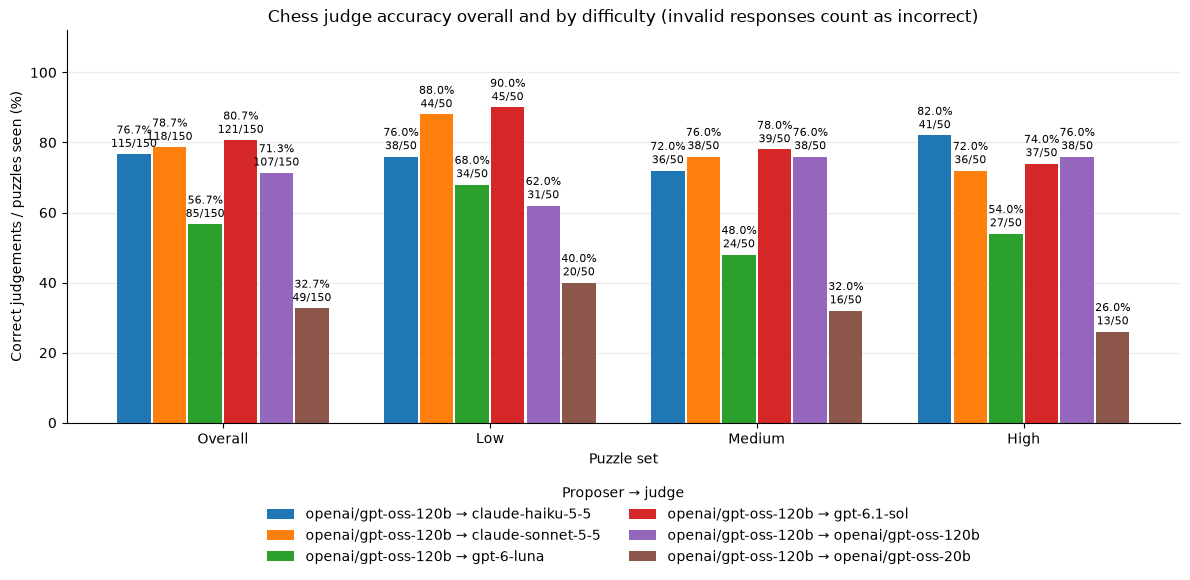

Saved chart: /Users/jacksonsubcleff/llm_debate/exp/chess_six_judged/figures/judge_accuracy_by_difficulty.png


In [16]:
BUCKETS = ["Low", "Medium", "High"]
bucket_summary = summarize_judgements(raw, by_bucket=True)
unknown_buckets = set(bucket_summary["rating_bucket"]) - set(BUCKETS)
if unknown_buckets:
    raise ValueError(f"Unexpected difficulty buckets: {sorted(unknown_buckets)}")
display(bucket_summary.style.format({"accuracy": "{:.1%}", "FPR": "{:.1%}",
                                     "FNR": "{:.1%}", "TPR": "{:.1%}", "TNR": "{:.1%}"}, na_rep="N/A"))
pairs = list(summary[["proposer", "judge"]].itertuples(index=False, name=None))
categories = ["Overall", *BUCKETS]
plot_summary = pd.concat([summary.assign(rating_bucket="Overall"), bucket_summary])
x = np.arange(len(categories))
width = 0.8 / len(pairs)
palette = plt.get_cmap("tab10")
fig_bucket, ax_bucket = plt.subplots(figsize=(max(9, len(pairs) * 2), 6))
for index, (proposer, judge) in enumerate(pairs):
    group = plot_summary[(plot_summary["proposer"] == proposer)
                         & (plot_summary["judge"] == judge)].set_index("rating_bucket").reindex(categories)
    values = group["accuracy"].to_numpy(dtype=float) * 100
    positions = x - 0.4 + width * (index + 0.5)
    ax_bucket.bar(positions, values, width=width * 0.94, color=palette(index % 10),
                  label=f"{proposer} → {judge}")
    for position, value, (_, row) in zip(positions, values, group.iterrows()):
        if np.isnan(value):
            ax_bucket.text(position, 1, "N/A", ha="center", va="bottom", fontsize=8, rotation=90)
        else:
            ax_bucket.text(position, value + 1, f"{value:.1f}%\n{int(row['correct_judgements'])}/{int(row['seen'])}",
                           ha="center", va="bottom", fontsize=8)
ax_bucket.set(xticks=x, xticklabels=categories, ylim=(0, 112),
              xlabel="Puzzle set", ylabel="Correct judgements / puzzles seen (%)",
              title="Chess judge accuracy overall and by difficulty (invalid responses count as incorrect)")
ax_bucket.set_yticks(np.arange(0, 101, 20))
ax_bucket.set_axisbelow(True)
ax_bucket.grid(axis="y", alpha=0.25)
ax_bucket.spines[["top", "right"]].set_visible(False)
ax_bucket.legend(title="Proposer → judge", loc="upper center", bbox_to_anchor=(0.5, -0.13),
                 ncol=min(2, len(pairs)), frameon=False)
fig_bucket.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
bucket_output_path = FIGURE_DIR / "judge_accuracy_by_difficulty.png"
fig_bucket.savefig(bucket_output_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved chart: {bucket_output_path}")


## Inspect an individual puzzle

Enter a puzzle ID and click **Show puzzle** to show every matching proposer/judge pairing, including incomplete judgements. Each report displays the solver's board (White at the bottom), the full **proposer output first**, and the full **judge output second**. The proposer text comes from the judge manifest's pinned input transcript, with the original proposer CSV as a fallback for older runs. Missing source data is reported explicitly.

Run the loading cell above to refresh results during an ongoing experiment. If widgets are unavailable, call `show_judge_puzzle("02im6")` directly after running the helper cell below.


In [17]:
from html import escape
import chess
import chess.svg
from IPython.display import HTML


def proposer_output_for(row):
    """Prefer the exact transcript the judge evaluated over a mutable source CSV."""
    result_file = Path(row.get("_result_file", ""))
    for parent in result_file.parents:
        manifest_path = parent / "chess_judge_run.json"
        if not manifest_path.is_file():
            continue
        try:
            sources = json.loads(manifest_path.read_text())["sources"]
            matches = [s for s in sources
                       if str(s.get("puzzleId")) == str(row["puzzleId"])
                       and s.get("proposer") == row["proposer"]
                       and s.get("source") == row.get("source")
                       and s.get("FEN") == row["FEN"]]
            if len(matches) == 1:
                return str(matches[0].get("model_response", "")), "Pinned judge input transcript"
        except (OSError, ValueError, KeyError, TypeError):
            pass
        break
    source = Path(str(row.get("source", "")))
    if source.is_file():
        try:
            proposals = pd.read_csv(source, keep_default_na=False, dtype={"puzzleId": str})
            match = proposals[(proposals["puzzleId"] == str(row["puzzleId"]))
                              & (proposals["model"] == row["proposer"])
                              & (proposals["FEN"] == row["FEN"])
                              & (proposals["final_move"] == row["proposed_solution"])]
            if len(match) == 1:
                return str(match.iloc[0]["model_response"]), "Original proposer CSV (current contents)"
        except (OSError, ValueError, KeyError):
            pass
    return "Proposer output unavailable: the pinned transcript and original proposer CSV could not be found or matched.", "Missing source data"


def judge_puzzle_html(row):
    board = chess.Board(row["FEN"])
    diagram = chess.svg.board(board, orientation=chess.WHITE, size=380,
                              check=board.king(board.turn) if board.is_check() else None)
    proposer_text, origin = proposer_output_for(row)
    judge_text = str(row.get("model_response", "")) or "No judge output saved yet."
    row = row.copy()
    row["judgement"] = saved_judgement(row)
    row["correct"] = (row["judgement"] in ("Yes", "No")
                      and (row["judgement"] == "Yes") == (str(row["proposer_correct"]).lower() == "true")
                      and has_normal_final_stop(row.get("tool_trace", "[]")))
    complete = str(row["complete"]).lower() == "true"
    judge_status = ("Correct" if str(row.get("correct", False)).lower() == "true" else "Incorrect") if complete else "Incomplete"
    proposal_status = "Correct" if str(row["proposer_correct"]).lower() == "true" else "Incorrect"
    def text(value):
        return escape(str(value))
    def output(value):
        return '<pre style="white-space:pre-wrap;overflow-wrap:anywhere;padding:12px;background:rgba(127,127,127,.08);border-radius:6px">' + text(value) + '</pre>'
    error = str(row.get("error", ""))
    return f"""<section style="border-bottom:1px solid #aaa;padding:16px 0">
      <h3>Puzzle {text(row['puzzleId'])}: {text(row['proposer'])} → {text(row['model'])}</h3>
      {diagram}
      <p><strong>Side to move:</strong> {'White' if board.turn else 'Black'}<br>
      <strong>FEN:</strong> <code>{text(row['FEN'])}</code><br>
      <strong>Proposed solution:</strong> {text(row['proposed_solution'])} ({proposal_status})<br>
      <strong>Judge verdict:</strong> {text(row.get('judgement', '')) or 'Unavailable'}; evaluation: {judge_status}</p>
      <h4>1. Proposer output — {text(row['proposer'])}</h4>
      <p><small>{text(origin)}</small></p>{output(proposer_text)}
      <h4>2. Judge output — {text(row['model'])}</h4>{output(judge_text)}
      {('<p><strong>Saved error:</strong> ' + text(error) + '</p>') if error else ''}
    </section>"""


def judge_puzzle_report(puzzle_id):
    """Build one HTML report without emitting notebook display messages."""
    puzzle_id = str(puzzle_id).strip()
    if not puzzle_id:
        return "<p>Enter a puzzle ID.</p>"
    matches = raw[raw["puzzleId"].astype(str).eq(puzzle_id)]
    if matches.empty:
        return (f"<p>No saved judge results for puzzle {escape(puzzle_id)!r} "
                f"in {escape(str(EXP_DIR))}.</p>")
    sections = [f"<p>Puzzle {escape(puzzle_id)}: {len(matches)} saved pairing(s)</p>"]
    for _, row in matches.sort_values(["proposer", "model"]).iterrows():
        try:
            sections.append(judge_puzzle_html(row))
        except ValueError as exc:
            sections.append(f"<p>Cannot display {escape(str(row['proposer']))} → "
                            f"{escape(str(row['model']))}: {escape(str(exc))}</p>")
    return "\n".join(sections)


def show_judge_puzzle(puzzle_id):
    display(HTML(judge_puzzle_report(puzzle_id)))


In [18]:
PUZZLE_ID = str(raw.iloc[0]["puzzleId"]) if not raw.empty else ""

try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets is unavailable. Edit PUZZLE_ID and rerun, or call show_judge_puzzle(id).")
    if PUZZLE_ID:
        show_judge_puzzle(PUZZLE_ID)
else:
    puzzle_input = widgets.Text(value=PUZZLE_ID, description="Puzzle ID:",
                                placeholder="e.g. 02im6", continuous_update=False)
    puzzle_button = widgets.Button(description="Show puzzle", button_style="primary", icon="search")
    # Update a single widget value instead of capturing rich display messages.
    # This avoids duplicate inline/Output rendering in notebook frontends.
    puzzle_output = widgets.HTML(layout=widgets.Layout(width="100%"))

    def _show_judge_puzzle(_=None):
        puzzle_output.value = judge_puzzle_report(puzzle_input.value)

    puzzle_button.on_click(_show_judge_puzzle)
    display(widgets.VBox([widgets.HBox([puzzle_input, puzzle_button]), puzzle_output]))
    _show_judge_puzzle()
